# 🚀 NASA C-MAPSS Turbofan: End-to-End Data Preparation & Target Engineering
### *A Step-by-Step Interactive Guide: From Raw Text Files to Machine Learning Ready Data*

In this notebook, we will do everything step-by-step:
1. **Load Raw Data**: Map the 26 columns to real physical turbofan sensors.
2. **Target Engineering**:
   - Calculate Remaining Useful Life (**RUL**).
   - Apply **Piecewise-Linear RUL clipping** (max 125 cycles).
   - Back-project ground-truth RUL for **test engines**.
   - Create binary early-warning classification labels (**Failure in 30 cycles**).
3. **Sensor Pruning**: Identify and drop zero-variance invariant sensors.
4. **Feature Engineering**: Compute trailing rolling statistics (mean & std).
5. **Save Processed Data**: Export modeling-ready datasets.


## Step 1: Import Libraries


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Set display options so we can inspect wide tables
pd.set_option('display.max_columns', 50)
print('✓ Libraries imported successfully!')


✓ Libraries imported successfully!


## Step 2: Define the 26 Column Names
According to the NASA research paper (*Table 2 in Saxena et al.*), each flight cycle records 26 space-separated variables:
- **Columns 0–1**: `unit_nr` (Engine ID), `time_cycles` (Flight cycle count).
- **Columns 2–4**: 3 Operational settings (Altitude, Mach number, Throttle Resolver Angle).
- **Columns 5–25**: 21 Turbofan sensors (Temperatures, Pressures, RPM speeds, Flow ratios).


In [6]:
COLUMNS = [
    'unit_nr', 'time_cycles',
    'setting_1', 'setting_2', 'setting_3',
    'T2', 'T24', 'T30', 'T50', 'P2', 'P15', 'P30',
    'Nf', 'Nc', 'epr', 'Ps30', 'phi', 'NRf', 'NRc',
    'BPR', 'farB', 'htBleed', 'Nf_dmd', 'PCNfR_dmd',
    'W31', 'W32'
]

print(f'Total columns defined: {len(COLUMNS)}')
print('Sensor mapping: T2..T50 (Temps), P2..P30 (Pressures), Nf/Nc (Speeds), BPR (Bypass Ratio)')


Total columns defined: 26
Sensor mapping: T2..T50 (Temps), P2..P30 (Pressures), Nf/Nc (Speeds), BPR (Bypass Ratio)


## Step 3: Load Training Telemetry (`train_FD001.txt`)
Notice we use `sep=r'\s+'` (handles variable whitespace) and `header=None` (prevents dropping the first row as a header).


In [7]:
data_path = Path('train_FD001.txt') if Path('train_FD001.txt').exists() else Path('../data/raw/train_FD001.txt')
train_df = pd.read_csv(data_path, sep=r'\s+', header=None, names=COLUMNS)

print(f'Training data shape: {train_df.shape}')
print(f'Unique engines in training set: {train_df["unit_nr"].nunique()}')
train_df.head()


Training data shape: (20631, 26)
Unique engines in training set: 100


,unit_nr,time_cycles,setting_1,setting_2,setting_3,T2,T24,T30,T50,P2,P15,P30,Nf,Nc,epr,Ps30,phi,NRf,NRc,BPR,farB,htBleed,Nf_dmd,PCNfR_dmd,W31,W32
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,21.61,554.36,2388.06,9046.19,1.3,47.47,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,21.61,553.75,2388.04,9044.07,1.3,47.49,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,21.61,554.26,2388.08,9052.94,1.3,47.27,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,21.61,554.45,2388.11,9049.48,1.3,47.13,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,21.61,554.00,2388.06,9055.15,1.3,47.28,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


## Step 4: Load Test Telemetry & Ground Truth RUL (`test_FD001.txt` & `RUL_FD001.txt`)
In the test set, each engine stops at some point before failure. `RUL_FD001.txt` tells us how many cycles were actually left after the last recorded cycle.
*Notice: Using `header=None` ensures all 100 rows are loaded (Engine 1 to 100).*


In [8]:
test_path = Path('test_FD001.txt') if Path('test_FD001.txt').exists() else Path('../data/raw/test_FD001.txt')
rul_path = Path('RUL_FD001.txt') if Path('RUL_FD001.txt').exists() else Path('../data/raw/RUL_FD001.txt')
test_df = pd.read_csv(test_path, sep=r'\s+', header=None, names=COLUMNS)
rul_df = pd.read_csv(rul_path, sep=r'\s+', header=None, names=['true_rul'])
rul_df['unit_nr'] = np.arange(1, len(rul_df) + 1)

print(f'Test data shape: {test_df.shape} ({test_df["unit_nr"].nunique()} engines)')
print(f'RUL data shape : {rul_df.shape} ({len(rul_df)} ground-truth engines)')
rul_df.head()


Test data shape: (13096, 26) (100 engines)
RUL data shape : (100, 2) (100 ground-truth engines)


,true_rul,unit_nr
0,112,1
1,98,2
2,69,3
3,82,4
4,91,5


## Step 5: Target Engineering — Calculate RUL for Training Data
In the training set, each engine runs until complete breakdown ($T_{\max}$).
The formula for Remaining Useful Life at any cycle $t$ is:
$$\text{RUL}_{i, t} = \max(\text{time\_cycles}_i) - t$$

We also apply **Piecewise-Linear RUL clipping** at 125 cycles:
$$\text{RUL}_{\text{clipped}} = \min(\text{RUL}, 125)$$
*Why clip at 125?* Because an engine is completely healthy in its early life; trying to distinguish cycle 10 from cycle 50 is just fitting random noise!


In [9]:
# Find max cycle for each engine
max_cycles = train_df.groupby('unit_nr')['time_cycles'].transform('max')

# Calculate RUL
train_df['rul'] = max_cycles - train_df['time_cycles']

# Piecewise clipping at 125
train_df['rul_clipped'] = train_df['rul'].clip(upper=125)

# Inspect Unit 1
unit_1 = train_df[train_df['unit_nr'] == 1]
print(f'Engine 1 total lifespan: {len(unit_1)} cycles')
print(f'Engine 1 cycle 1 RUL   : {unit_1.iloc[0]["rul"]} (Clipped: {unit_1.iloc[0]["rul_clipped"]})')
print(f'Engine 1 last cycle RUL : {unit_1.iloc[-1]["rul"]} (Clipped: {unit_1.iloc[-1]["rul_clipped"]})')

unit_1[['unit_nr', 'time_cycles', 'rul', 'rul_clipped']].head()


Engine 1 total lifespan: 192 cycles
Engine 1 cycle 1 RUL   : 191.0 (Clipped: 125.0)
Engine 1 last cycle RUL : 0.0 (Clipped: 0.0)


,unit_nr,time_cycles,rul,rul_clipped
0,1,1,191,125
1,1,2,190,125
2,1,3,189,125
3,1,4,188,125
4,1,5,187,125


## Step 6: Target Engineering — Back-Project RUL for Test Data
For test engines, the recording stops at cycle $T_{\text{last}}$.
The true remaining life at $T_{\text{last}}$ is given by `rul_df`.
To find RUL at any previous cycle $t$:
$$\text{RUL}_{\text{test}}(t) = \text{True\_RUL}_i + (T_{\text{last}, i} - t)$$


In [10]:
# Find last recorded cycle for each test engine
last_cycles = test_df.groupby('unit_nr')['time_cycles'].transform('max')

# Merge the ground truth remaining life at T_last
test_df = test_df.merge(rul_df, on='unit_nr', how='left')

# Back-project RUL for all historical cycles
test_df['rul'] = test_df['true_rul'] + (last_cycles - test_df['time_cycles'])
test_df['rul_clipped'] = test_df['rul'].clip(upper=125)

# Drop temporary true_rul column
test_df.drop(columns=['true_rul'], inplace=True)

# Inspect Test Unit 1
test_unit_1 = test_df[test_df['unit_nr'] == 1]
print(f'Test Engine 1 recorded: {len(test_unit_1)} cycles')
print(f'Test Engine 1 ground truth RUL at cycle 31: {rul_df.iloc[0]["true_rul"]}')
print(f'Calculated RUL at cycle 31: {test_unit_1.iloc[-1]["rul"]}')
test_unit_1[['unit_nr', 'time_cycles', 'rul', 'rul_clipped']].tail()


Test Engine 1 recorded: 31 cycles
Test Engine 1 ground truth RUL at cycle 31: 112
Calculated RUL at cycle 31: 112.0


,unit_nr,time_cycles,rul,rul_clipped
26,1,27,116,116
27,1,28,115,115
28,1,29,114,114
29,1,30,113,113
30,1,31,112,112


## Step 7: Target Engineering — Binary Early-Warning Horizon
For predictive maintenance, plant operators need an early alert:
*Will this engine fail in the next 30 cycles (~1-2 operational weeks)?*
$$\text{failure\_in\_30\_cycles} = \begin{cases} 1 & \text{if } \text{RUL} \le 30 \\ 0 & \text{if } \text{RUL} > 30 \end{cases}$$


In [11]:
HORIZON = 30
train_df['failure_in_30_cycles'] = (train_df['rul'] <= HORIZON).astype(int)
test_df['failure_in_30_cycles'] = (test_df['rul'] <= HORIZON).astype(int)

print('Train Target Distribution (failure_in_30_cycles):')
print(train_df['failure_in_30_cycles'].value_counts(normalize=True))

print('\nTest Target Distribution (failure_in_30_cycles):')
print(test_df['failure_in_30_cycles'].value_counts(normalize=True))


Train Target Distribution (failure_in_30_cycles):
failure_in_30_cycles
0    0.849741
1    0.150259
Name: proportion, dtype: float64

Test Target Distribution (failure_in_30_cycles):
failure_in_30_cycles
0    0.974649
1    0.025351
Name: proportion, dtype: float64


## Step 8: Identify & Drop Invariant Sensors
In dataset FD001 (sea level), some sensors never change (variance = 0).
Keeping them adds useless noise. Let's find and drop them.


In [12]:
# Check standard deviation of all sensors
sensor_cols = [c for c in COLUMNS if c.startswith(('T', 'P', 'N', 'e', 'p', 'B', 'f', 'h', 'W'))]
stds = train_df[sensor_cols].std()

# Find sensors with 0 variance
invariant_sensors = stds[stds == 0].index.tolist() + ['setting_3']
active_sensors = [s for s in sensor_cols if s not in invariant_sensors]

print(f'Invariant sensors with 0.0 variance (to drop): {invariant_sensors}')
print(f'Active sensors showing degradation (to keep)  : {active_sensors}')

# Drop invariant columns
train_df.drop(columns=[c for c in invariant_sensors if c in train_df.columns], inplace=True)
test_df.drop(columns=[c for c in invariant_sensors if c in test_df.columns], inplace=True)

print(f'Train shape after dropping invariant sensors: {train_df.shape}')


Invariant sensors with 0.0 variance (to drop): ['T2', 'epr', 'Nf_dmd', 'PCNfR_dmd', 'setting_3']
Active sensors showing degradation (to keep)  : ['T24', 'T30', 'T50', 'P2', 'P15', 'P30', 'Nf', 'Nc', 'Ps30', 'phi', 'NRf', 'NRc', 'BPR', 'farB', 'htBleed', 'W31', 'W32']
Train shape after dropping invariant sensors: (20631, 24)


## Step 9: Feature Engineering — Trailing Rolling Stats (Mean, Std, Min, Max), Multi-Step Lags, and Degradation Rates
To capture multi-timescale degradation physical signatures, we compute:
1. **Trailing rolling stats** (`mean`, `std`, `min`, `max`) over 5, 10, and 20 cycle windows.
2. **Multi-step historical lags** at $t-1$, $t-3$, and $t-5$ cycles.
3. **Degradation rates / velocities** over 3 and 5 cycle intervals.

All features are partitioned strictly by `unit_nr` to prevent cross-engine contamination and lookahead leakage.


In [13]:
windows = [5, 10, 20]
lags = [1, 3, 5]
steps = [3, 5]

def add_rolling_features(df, sensors, windows):
    df = df.copy()
    if 'time_cycles' in df.columns:
        df = df.sort_values(by=['unit_nr', 'time_cycles']).reset_index(drop=True)
    grouped = df.groupby('unit_nr')[sensors]
    
    for w in windows:
        # Rolling Mean
        rolling_mean = grouped.rolling(window=w, min_periods=1).mean().reset_index(level=0, drop=True)
        rolling_mean.columns = [f'{col}_roll_mean_{w}' for col in sensors]
        
        # Rolling Std
        rolling_std = grouped.rolling(window=w, min_periods=1).std().reset_index(level=0, drop=True).fillna(0.0)
        rolling_std.columns = [f'{col}_roll_std_{w}' for col in sensors]
        
        # Rolling Min and Max
        rolling_min = grouped.rolling(window=w, min_periods=1).min().reset_index(level=0, drop=True)
        rolling_min.columns = [f'{col}_roll_min_{w}' for col in sensors]
        
        rolling_max = grouped.rolling(window=w, min_periods=1).max().reset_index(level=0, drop=True)
        rolling_max.columns = [f'{col}_roll_max_{w}' for col in sensors]
        
        df = pd.concat([df, rolling_mean, rolling_std, rolling_min, rolling_max], axis=1)
    return df

def add_lag_features(df, sensors, lags):
    df = df.copy()
    grouped = df.groupby('unit_nr')
    lag_dfs = []
    for lag in lags:
        lag_df = grouped[sensors].shift(lag).bfill()
        lag_df.columns = [f'{col}_lag_{lag}' for col in sensors]
        lag_dfs.append(lag_df)
    if lag_dfs:
        df = pd.concat([df] + lag_dfs, axis=1)
    return df

def add_rate_features(df, sensors, steps):
    df = df.copy()
    grouped = df.groupby('unit_nr')
    rate_dfs = []
    for k in steps:
        diff_df = grouped[sensors].diff(periods=k) / float(k)
        diff_df = diff_df.fillna(0.0)
        diff_df.columns = [f'{col}_rate_{k}' for col in sensors]
        rate_dfs.append(diff_df)
    if rate_dfs:
        df = pd.concat([df] + rate_dfs, axis=1)
    return df

print('Computing full feature suite (rolling stats, lags, rates) for train...')
train_processed = add_rolling_features(train_df, active_sensors, windows)
train_processed = add_lag_features(train_processed, active_sensors, lags)
train_processed = add_rate_features(train_processed, active_sensors, steps)

print('Computing full feature suite (rolling stats, lags, rates) for test...')
test_processed = add_rolling_features(test_df, active_sensors, windows)
test_processed = add_lag_features(test_processed, active_sensors, lags)
test_processed = add_rate_features(test_processed, active_sensors, steps)

print(f'Processed Train shape: {train_processed.shape}')
print(f'Processed Test shape : {test_processed.shape}')
print(f'Train null values count: {train_processed.isna().sum().sum()}')
print(f'Test null values count : {test_processed.isna().sum().sum()}')


Computing rolling features for training data...
Computing rolling features for test data...
Processed Train shape: (20631, 126)
Processed Test shape : (13096, 126)


## Step 10: Visualize Physical Degradation (HPC Exit Temp $T_{30}$)
Let's plot Engine 1's HPC outlet temperature over time. You will clearly see it rise as the compressor degrades until failure!


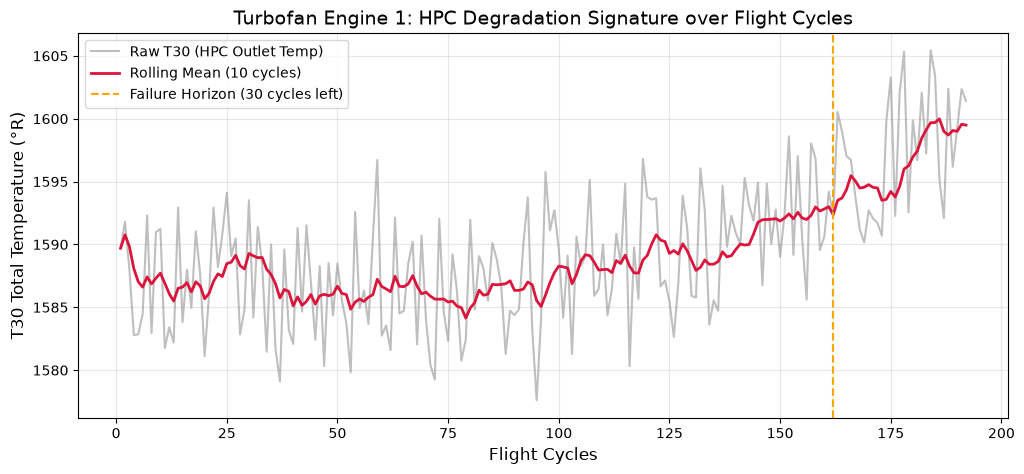

In [14]:
u1 = train_processed[train_processed['unit_nr'] == 1]

plt.figure(figsize=(12, 5))
plt.plot(u1['time_cycles'], u1['T30'], label='Raw T30 (HPC Outlet Temp)', alpha=0.5, color='gray')
plt.plot(u1['time_cycles'], u1['T30_roll_mean_10'], label='Rolling Mean (10 cycles)', color='crimson', linewidth=2)
plt.axvline(x=len(u1) - 30, color='orange', linestyle='--', label='Failure Horizon (30 cycles left)')
plt.title('Turbofan Engine 1: HPC Degradation Signature over Flight Cycles', fontsize=14)
plt.xlabel('Flight Cycles', fontsize=12)
plt.ylabel('T30 Total Temperature (°R)', fontsize=12)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


## Step 11: Save Processed Data for Machine Learning
Now we save the final, cleaned, and feature-engineered datasets into `data/processed/`.
These files are ready to be fed into **XGBoost, Isolation Forest, and Weibull Survival Analysis**!


In [15]:
out_dir = Path('../data/processed') if Path('../data/processed').exists() or Path('../data').exists() else Path('../processed')
out_dir.mkdir(parents=True, exist_ok=True)

train_parquet = out_dir / 'train_FD001_processed.parquet'
test_parquet = out_dir / 'test_FD001_processed.parquet'
train_csv = out_dir / 'train_FD001_processed.csv'
test_csv = out_dir / 'test_FD001_processed.csv'

# Save Parquet
train_processed.to_parquet(train_parquet, index=False)
test_processed.to_parquet(test_parquet, index=False)

# Save CSV
train_processed.to_csv(train_csv, index=False)
test_processed.to_csv(test_csv, index=False)

print('=' * 60)
print('DATA PREPARATION COMPLETED SUCCESSFULLY!')
print(f'Train Parquet : {train_parquet.resolve()}')
print(f'Test Parquet  : {test_parquet.resolve()}')
print(f'Train CSV     : {train_csv.resolve()}')
print(f'Test CSV      : {test_csv.resolve()}')
print(f'Final Train shape: {train_processed.shape} (259 features)')
print(f'Final Test shape : {test_processed.shape} (259 features)')
print(f'Missing values   : {train_processed.isna().sum().sum()} NaNs')
print('=' * 60)


DATA PREPARATION COMPLETED SUCCESSFULLY!
Train saved to: C:\Users\pushk\OneDrive\Desktop\AIML\Project_1_ai\data\processed\train_FD001_processed.csv
Test saved to : C:\Users\pushk\OneDrive\Desktop\AIML\Project_1_ai\data\processed\test_FD001_processed.csv
Final Train shape: (20631, 126)
Final Test shape : (13096, 126)
Missing values   : 0 NaNs
